In [3]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from lightgbm import LGBMRegressor

In [4]:
df = pd.read_pickle("../data/processed/fd001_basis_c.pkl")
feature_cols = [c for c in df.columns if c not in ["unit", "RUL"]]

In [5]:
X = df[feature_cols]
y = df["RUL"]

model = LGBMRegressor(verbose = -1, n_jobs = 1, random_state=42)
model.fit(X, y)

,random_state,42
,n_jobs,1
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [6]:
explainer = shap.TreeExplainer(model)
shap_werte = explainer.shap_values(X)

In [7]:
shap_werte.shape

(20631, 98)

In [8]:
np.allclose(model.predict(X), (shap_werte.sum(axis=1) + explainer.expected_value))

True

In [9]:
print(explainer.expected_value)
print(y.mean())

86.82928602578225
86.82928602588338


In [10]:
feature_shap = np.abs(shap_werte).mean(axis = 0)
feature_importance = pd.Series(feature_shap, index = feature_cols)
feature_importance.sort_values(ascending=False).head(10)

s4_mean5       7.540240
s15_mean5      3.734426
s11_slope25    3.448518
s11_mean5      2.717997
s12_slope25    2.672856
s9_slope25     2.330824
s8_slope25     2.208033
s2_mean5       2.107821
s14_slope25    2.070767
s13_slope25    1.898039
dtype: float64

In [11]:
sensor_namen = []
typen = []

for col in feature_cols:
    teile = col.split("_", 1)
    sensor_namen.append(teile[0])
    if len(teile)==1:
        name = "roh"
        typen.append(name)
    else:
        typen.append(teile[1])


shap_df = pd.DataFrame({
    "feature": feature_cols,
    "wichtigkeit": feature_importance.to_numpy(),
    "sensor": sensor_namen,
    "typ": typen,
})


shap_df

,feature,wichtigkeit,sensor,typ
0,s2,0.000000,s2,roh
1,s3,0.004061,s3,roh
2,s4,0.001866,s4,roh
3,s8,0.000000,s8,roh
4,s11,0.000000,s11,roh
...,...,...,...,...
93,s12_slope25,2.672856,s12,slope25
94,s20_slope25,1.021076,s20,slope25
95,s21_slope25,1.063290,s21,slope25
96,s9_slope25,2.330824,s9,slope25


In [12]:
shap_df.groupby("typ")["wichtigkeit"].sum().sort_values(ascending=False)

typ
slope25     23.146532
mean5       22.291218
mean25       7.673696
std25        3.144533
diff5_25     0.679464
std5         0.288214
roh          0.094265
Name: wichtigkeit, dtype: float64

In [13]:
shap_df.groupby("sensor")["wichtigkeit"].sum().sort_values(ascending = False)

sensor
s4     9.440385
s11    6.867632
s15    5.456796
s9     5.172837
s14    4.273642
s2     3.872677
s12    3.475552
s8     3.129451
s21    2.750167
s17    2.710189
s7     2.703006
s20    2.601898
s13    2.547243
s3     2.316447
Name: wichtigkeit, dtype: float64

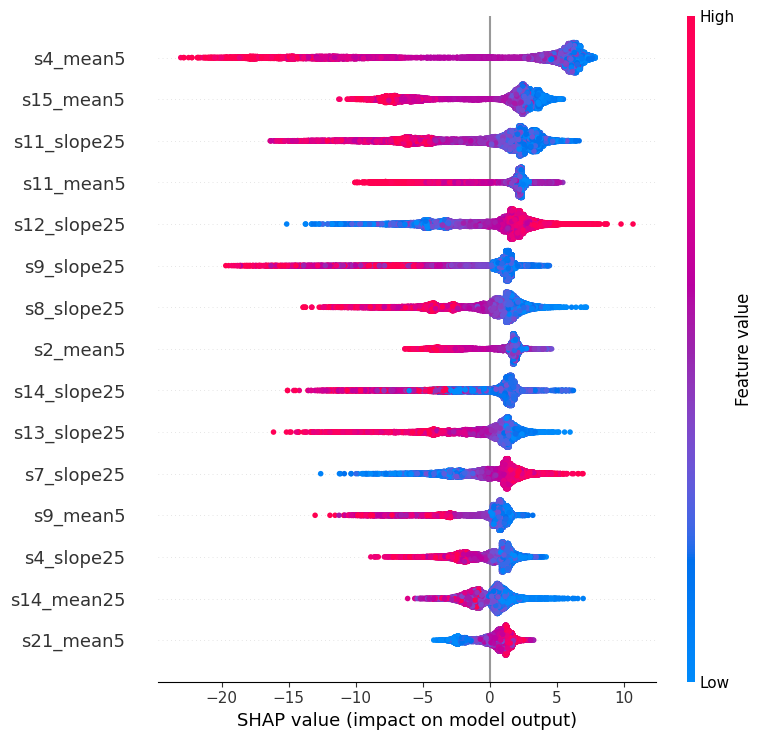

In [14]:
shap.summary_plot(shap_werte, X, max_display=15)

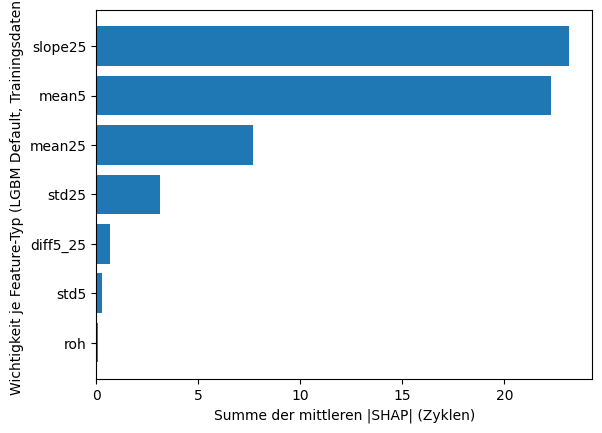

In [24]:
typ_werte = shap_df.groupby("typ")["wichtigkeit"].sum().sort_values(ascending=True)

plt.barh(typ_werte.index, typ_werte.values)
plt.xlabel("Summe der mittleren |SHAP| (Zyklen)")
plt.ylabel("Wichtigkeit je Feature-Typ (LGBM Default, Trainingsdaten)")
plt.show()